# Testing DLP: Training a Basic FNN

In this notebook, we construct and run a basic FNN to make sure that functionality is established. Creation Date: July 27 2018.

In [1]:
import sys
PYTHONPATH="../"
sys.path.append(PYTHONPATH)
import models 
from train import * 
import matplotlib.pyplot as py 
%matplotlib inline 

Using TensorFlow backend.


In [2]:
# first, let's generate the input data 
# this function is contained in train.py 
train_file = "../Preprocess/preprocess_outputs/train_DLP_Test.h5"
val_file = "../Preprocess/preprocess_outputs/val_DLP_Test.h5"
weight_file = "../Preprocess/preprocess_outputs/weight_DLP_Test.h5"
num_classes = 3
X_train, X_val, Y_train, Y_val, X_weights = models.fnn_input(train_file, val_file, weight_file, num_classes)

In [3]:
# let's explore the output of fnn_input to make sure it's correctly formatted 
type(X_train) # --> numpy array 
print(X_train.shape)
# shape is (979, 46) --> 979 jets, 46 variables per jet 
print(X_val.shape) 
print(Y_train.shape)
print(Y_val.shape)
print(X_weights.shape)
# looks like the validation set has one less jet than the training set 
# in this data; not sure why this is the case 

(979, 46)
(978, 46)
(979, 3)
(978, 3)
(979,)


In [4]:
# let's try to construct a one-layer FNN with our FNN class 
num_vars = X_train.shape[1] 
num_jets = X_train.shape[0]
print(num_jets)
print(num_vars)

# construct the model 
myModel = models.FNN(input_dim=num_vars, num_hidden=1, hidden_dims=[100], modelName="first_test")

979
46


In [5]:
# now that the model is contructed, let's do some training 
hyperParams = [1e-5, 0, 0, 50, 50]
first_history = fnn_train(myModel, X_train, X_val, Y_train, Y_val, X_weights, hyperParams, filepath="../Results/first_test.h5")

Train on 979 samples, validate on 978 samples
Epoch 1/50
979/979 [==============================] - 0s - loss: 1.6471 - acc: 0.3810 - val_loss: 1.2419 - val_acc: 0.3374
Epoch 2/50
979/979 [==============================] - 0s - loss: 1.6343 - acc: 0.3902 - val_loss: 1.2235 - val_acc: 0.3436
Epoch 3/50
979/979 [==============================] - 0s - loss: 1.5355 - acc: 0.4096 - val_loss: 1.2091 - val_acc: 0.3538
Epoch 4/50
979/979 [==============================] - 0s - loss: 1.6253 - acc: 0.4086 - val_loss: 1.1976 - val_acc: 0.3773
Epoch 5/50
979/979 [==============================] - 0s - loss: 1.6036 - acc: 0.4076 - val_loss: 1.1891 - val_acc: 0.4059
Epoch 6/50
979/979 [==============================] - 0s - loss: 1.5846 - acc: 0.4168 - val_loss: 1.1820 - val_acc: 0.4315
Epoch 7/50
979/979 [==============================] - 0s - loss: 1.5646 - acc: 0.4086 - val_loss: 1.1775 - val_acc: 0.4499
Epoch 8/50
979/979 [==============================] - 0s - loss: 1.5425 - acc: 0.4208 - val_l

In [6]:
# looks like it works! 
# let's explore the output 
type(first_history)

keras.callbacks.History

In [7]:
print(first_history.history.keys())

['acc', 'loss', 'val_acc', 'val_loss']


In [8]:
# so first_history.history is a dictionary with the above keys 
print(first_history.history['val_acc'])

[0.3374233167610895, 0.34355828662713367, 0.35378323144951723, 0.37730061210280547, 0.40593046783364867, 0.43149284192633286, 0.44989775118164732, 0.46114519335984694, 0.47750511576549165, 0.48261759142202831, 0.48977505490336193, 0.4938650366475002, 0.50102249403428933, 0.50511246968388313, 0.51022495295860038, 0.5143149347027387, 0.51738241692749753, 0.52044990171196515, 0.5235173857346147, 0.5235173857346147, 0.52658487204271831, 0.52760736595511681, 0.53067485073958442, 0.53271983932619937, 0.53374233323859777, 0.53680982107033759, 0.53885480889513448, 0.54192229215596599, 0.54498977694043349, 0.54703476324159428, 0.54907975106639118, 0.55214723786205844, 0.555214724840562, 0.55725971571263111, 0.55828220962502961, 0.55930470658470033, 0.56237219033309527, 0.56339468729276598, 0.56646217256479714, 0.56646217256479714, 0.56850716343686625, 0.56850716343686625, 0.56748466800083164, 0.56850716496050235, 0.56952965887290086, 0.57464213367620132, 0.57668712150099821, 0.57668712150099821

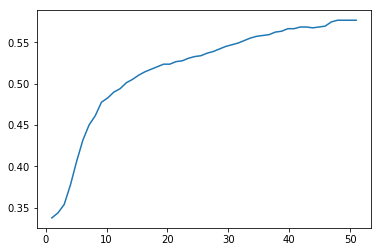

In [9]:
# let's try to make a simple plot of epoch vs. validation accuracy 
epochs = np.linspace(1, 51)
val_acc = first_history.history['val_acc']
py.plot(epochs, val_acc)

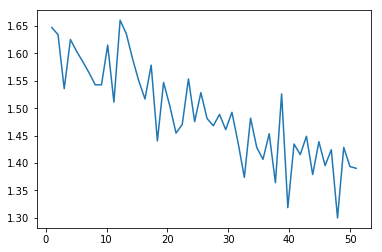

In [10]:
loss = first_history.history['loss']
py.plot(epochs, loss)